In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/vehicle-type-classification/vehicle_train_10000.csv
/kaggle/input/competitions/vehicle-type-classification/vehicle_test.csv
/kaggle/input/competitions/vehicle-type-classification/vehicle_sample_submission.csv


In [2]:
import pandas as pd
import numpy as np

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV,
    cross_val_score
)
from sklearn.metrics import accuracy_score, balanced_accuracy_score

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        if file.endswith(".csv"):
            print(os.path.join(root, file))

/kaggle/input/competitions/vehicle-type-classification/vehicle_train_10000.csv
/kaggle/input/competitions/vehicle-type-classification/vehicle_test.csv
/kaggle/input/competitions/vehicle-type-classification/vehicle_sample_submission.csv


In [4]:
TRAIN_PATH = "/kaggle/input/competitions/vehicle-type-classification/vehicle_train_10000.csv"
TEST_PATH = "/kaggle/input/competitions/vehicle-type-classification/vehicle_test.csv"

train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)

print("Training shape:", train_df.shape)
print("Test shape:", test_df.shape)

display(train_df.head())
display(test_df.head())

Training shape: (10000, 22)
Test shape: (2500, 21)


,vehicle_id,engine_displacement_l,horsepower_hp,vehicle_weight_kg,wheelbase_mm,vehicle_length_mm,vehicle_width_mm,vehicle_height_mm,fuel_tank_capacity_l,city_fuel_efficiency_kmpl,...,torque_nm,ground_clearance_mm,turning_radius_m,cargo_capacity_l,acceleration_0_100_kmh_s,braking_distance_m,tire_width_mm,drag_coefficient,battery_capacity_kwh,vehicle_class
0,1,2.56,290.0,1532.0,2737.0,4538.0,1814.0,1544.0,65.0,9.69,...,438.0,197.0,6.05,656.0,5.87,43.0,267.0,0.34,79.0,2
1,2,2.70,350.0,1529.0,2726.0,4473.0,1848.0,1636.0,62.0,10.35,...,441.0,251.0,5.30,513.0,6.48,41.0,247.0,0.28,76.0,2
2,3,2.50,335.0,1100.0,2504.0,3900.0,1650.0,1251.0,35.0,13.70,...,471.0,110.0,5.58,150.0,3.90,29.0,261.0,0.23,89.0,2
3,4,3.00,345.0,2069.0,3053.0,5134.0,2036.0,1572.0,81.0,10.72,...,478.0,168.0,6.36,626.0,6.20,51.0,283.0,0.37,60.0,1
4,5,1.59,155.0,1574.0,2791.0,4678.0,1804.0,1492.0,60.0,13.55,...,235.0,179.0,5.43,447.0,10.15,47.0,201.0,0.34,43.0,1


,vehicle_id,engine_displacement_l,horsepower_hp,vehicle_weight_kg,wheelbase_mm,vehicle_length_mm,vehicle_width_mm,vehicle_height_mm,fuel_tank_capacity_l,city_fuel_efficiency_kmpl,...,engine_cylinders,torque_nm,ground_clearance_mm,turning_radius_m,cargo_capacity_l,acceleration_0_100_kmh_s,braking_distance_m,tire_width_mm,drag_coefficient,battery_capacity_kwh
0,10001,2.17,279.0,1632.0,2752.0,4625.0,1805.0,1695.0,59.0,12.47,...,6.0,355.0,183.0,5.98,576.0,8.63,41.0,234.0,0.31,65.0
1,10002,1.61,189.0,1387.0,2618.0,4440.0,1766.0,1410.0,46.0,14.13,...,5.0,267.0,113.0,4.72,244.0,8.73,36.0,187.0,0.27,66.0
2,10003,3.00,375.0,2035.0,2990.0,5185.0,2016.0,1614.0,83.0,8.77,...,7.0,505.0,206.0,6.22,683.0,6.06,52.0,295.0,0.37,70.0
3,10004,2.45,316.0,1169.0,2543.0,4272.0,1698.0,1338.0,35.0,13.29,...,6.0,451.0,110.0,5.74,212.0,5.05,29.0,254.0,0.27,79.0
4,10005,3.08,321.0,2262.0,3063.0,5358.0,2050.0,1509.0,83.0,8.69,...,6.0,481.0,149.0,6.48,586.0,6.94,55.0,306.0,0.37,59.0


In [5]:
TARGET = "vehicle_class"
ID_COLUMN = "vehicle_id"

assert TARGET in train_df.columns, f"Missing target column: {TARGET}"

y = train_df[TARGET].copy()

feature_columns = [
    col for col in train_df.columns
    if col not in [TARGET, ID_COLUMN]
]

X = train_df[feature_columns].copy()

# Keep test features in the same column order
X_test = test_df[feature_columns].copy()

print("Feature matrix:", X.shape)
print("Target:", y.shape)
print("Test feature matrix:", X_test.shape)

print("\nTarget distribution:")
print(y.value_counts().sort_index())

print("\nMissing values in training features:", X.isnull().sum().sum())
print("Missing values in test features:", X_test.isnull().sum().sum())

Feature matrix: (10000, 20)
Target: (10000,)
Test feature matrix: (2500, 20)

Target distribution:
vehicle_class
0    3389
1    3326
2    3285
Name: count, dtype: int64

Missing values in training features: 0
Missing values in test features: 0


In [6]:
print("Training data shape:", train_df.shape)
print("Test data shape:", test_df.shape)

print("\nTraining dataset information:")
train_df.info()

print("\nStatistical summary:")
display(train_df.describe().T)

print("\nData types:")
display(train_df.dtypes.to_frame("Data Type"))

Training data shape: (10000, 22)
Test data shape: (2500, 21)

Training dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 22 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   vehicle_id                    10000 non-null  int64  
 1   engine_displacement_l         10000 non-null  float64
 2   horsepower_hp                 10000 non-null  float64
 3   vehicle_weight_kg             10000 non-null  float64
 4   wheelbase_mm                  10000 non-null  float64
 5   vehicle_length_mm             10000 non-null  float64
 6   vehicle_width_mm              10000 non-null  float64
 7   vehicle_height_mm             10000 non-null  float64
 8   fuel_tank_capacity_l          10000 non-null  float64
 9   city_fuel_efficiency_kmpl     10000 non-null  float64
 10  highway_fuel_efficiency_kmpl  10000 non-null  float64
 11  engine_cylinders            

,count,mean,std,min,25%,50%,75%,max
vehicle_id,10000.0,5000.500000,2886.895680,1.00,2500.7500,5000.50,7500.25,10000.00
engine_displacement_l,10000.0,2.425913,0.614435,0.90,2.0000,2.43,2.85,4.44
horsepower_hp,10000.0,296.495000,95.563811,90.00,226.0000,294.00,364.00,550.00
vehicle_weight_kg,10000.0,1636.399900,306.182383,1100.00,1409.0000,1604.00,1852.00,2600.00
wheelbase_mm,10000.0,2778.057600,172.346621,2400.00,2651.0000,2756.00,2906.00,3300.00
vehicle_length_mm,10000.0,4660.038600,366.060305,3900.00,4387.7500,4622.00,4937.00,5400.00
vehicle_width_mm,10000.0,1836.671100,117.744583,1650.00,1744.0000,1824.00,1928.00,2050.00
vehicle_height_mm,10000.0,1528.945000,145.978909,1250.00,1423.0000,1530.00,1634.00,2050.00
fuel_tank_capacity_l,10000.0,61.096000,14.511383,35.00,50.0000,60.00,72.00,90.00
city_fuel_efficiency_kmpl,10000.0,11.612495,2.565865,7.00,9.7500,11.56,13.36,20.87



Data types:


,Data Type
vehicle_id,int64
engine_displacement_l,float64
horsepower_hp,float64
vehicle_weight_kg,float64
wheelbase_mm,float64
vehicle_length_mm,float64
vehicle_width_mm,float64
vehicle_height_mm,float64
fuel_tank_capacity_l,float64
city_fuel_efficiency_kmpl,float64


In [7]:
print("Missing values in training data:")
display(train_df.isnull().sum().sort_values(ascending=False))

print("\nMissing values in test data:")
display(test_df.isnull().sum().sort_values(ascending=False))

print("\nExact duplicate rows in training:", train_df.duplicated().sum())

print(
    "Duplicate feature rows in training:",
    train_df.duplicated(subset=X.columns).sum()
)

if ID_COLUMN in train_df.columns:
    print("Duplicate training IDs:", train_df[ID_COLUMN].duplicated().sum())

if ID_COLUMN in test_df.columns:
    print("Duplicate test IDs:", test_df[ID_COLUMN].duplicated().sum())

Missing values in training data:


vehicle_id                      0
engine_displacement_l           0
horsepower_hp                   0
vehicle_weight_kg               0
wheelbase_mm                    0
vehicle_length_mm               0
vehicle_width_mm                0
vehicle_height_mm               0
fuel_tank_capacity_l            0
city_fuel_efficiency_kmpl       0
highway_fuel_efficiency_kmpl    0
engine_cylinders                0
torque_nm                       0
ground_clearance_mm             0
turning_radius_m                0
cargo_capacity_l                0
acceleration_0_100_kmh_s        0
braking_distance_m              0
tire_width_mm                   0
drag_coefficient                0
battery_capacity_kwh            0
vehicle_class                   0
dtype: int64


Missing values in test data:


vehicle_id                      0
engine_displacement_l           0
horsepower_hp                   0
vehicle_weight_kg               0
wheelbase_mm                    0
vehicle_length_mm               0
vehicle_width_mm                0
vehicle_height_mm               0
fuel_tank_capacity_l            0
city_fuel_efficiency_kmpl       0
highway_fuel_efficiency_kmpl    0
engine_cylinders                0
torque_nm                       0
ground_clearance_mm             0
turning_radius_m                0
cargo_capacity_l                0
acceleration_0_100_kmh_s        0
braking_distance_m              0
tire_width_mm                   0
drag_coefficient                0
battery_capacity_kwh            0
dtype: int64


Exact duplicate rows in training: 0
Duplicate feature rows in training: 2500
Duplicate training IDs: 0
Duplicate test IDs: 0


vehicle_class
0    3389
1    3326
2    3285
Name: count, dtype: int64

Class proportions:
vehicle_class
0    33.89
1    33.26
2    32.85
Name: proportion, dtype: float64


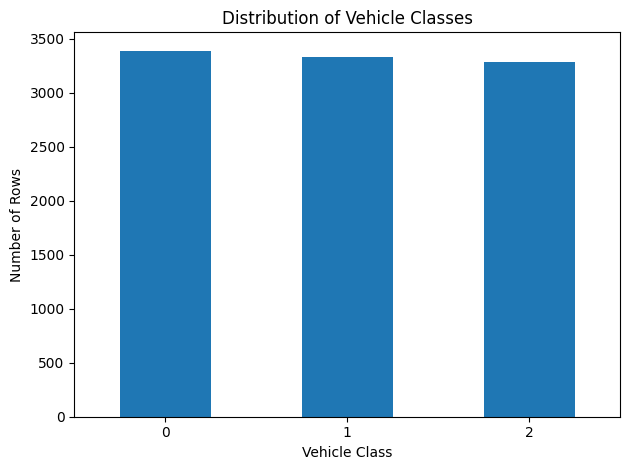

Number of numerical features: 20
['engine_displacement_l', 'horsepower_hp', 'vehicle_weight_kg', 'wheelbase_mm', 'vehicle_length_mm', 'vehicle_width_mm', 'vehicle_height_mm', 'fuel_tank_capacity_l', 'city_fuel_efficiency_kmpl', 'highway_fuel_efficiency_kmpl', 'engine_cylinders', 'torque_nm', 'ground_clearance_mm', 'turning_radius_m', 'cargo_capacity_l', 'acceleration_0_100_kmh_s', 'braking_distance_m', 'tire_width_mm', 'drag_coefficient', 'battery_capacity_kwh']


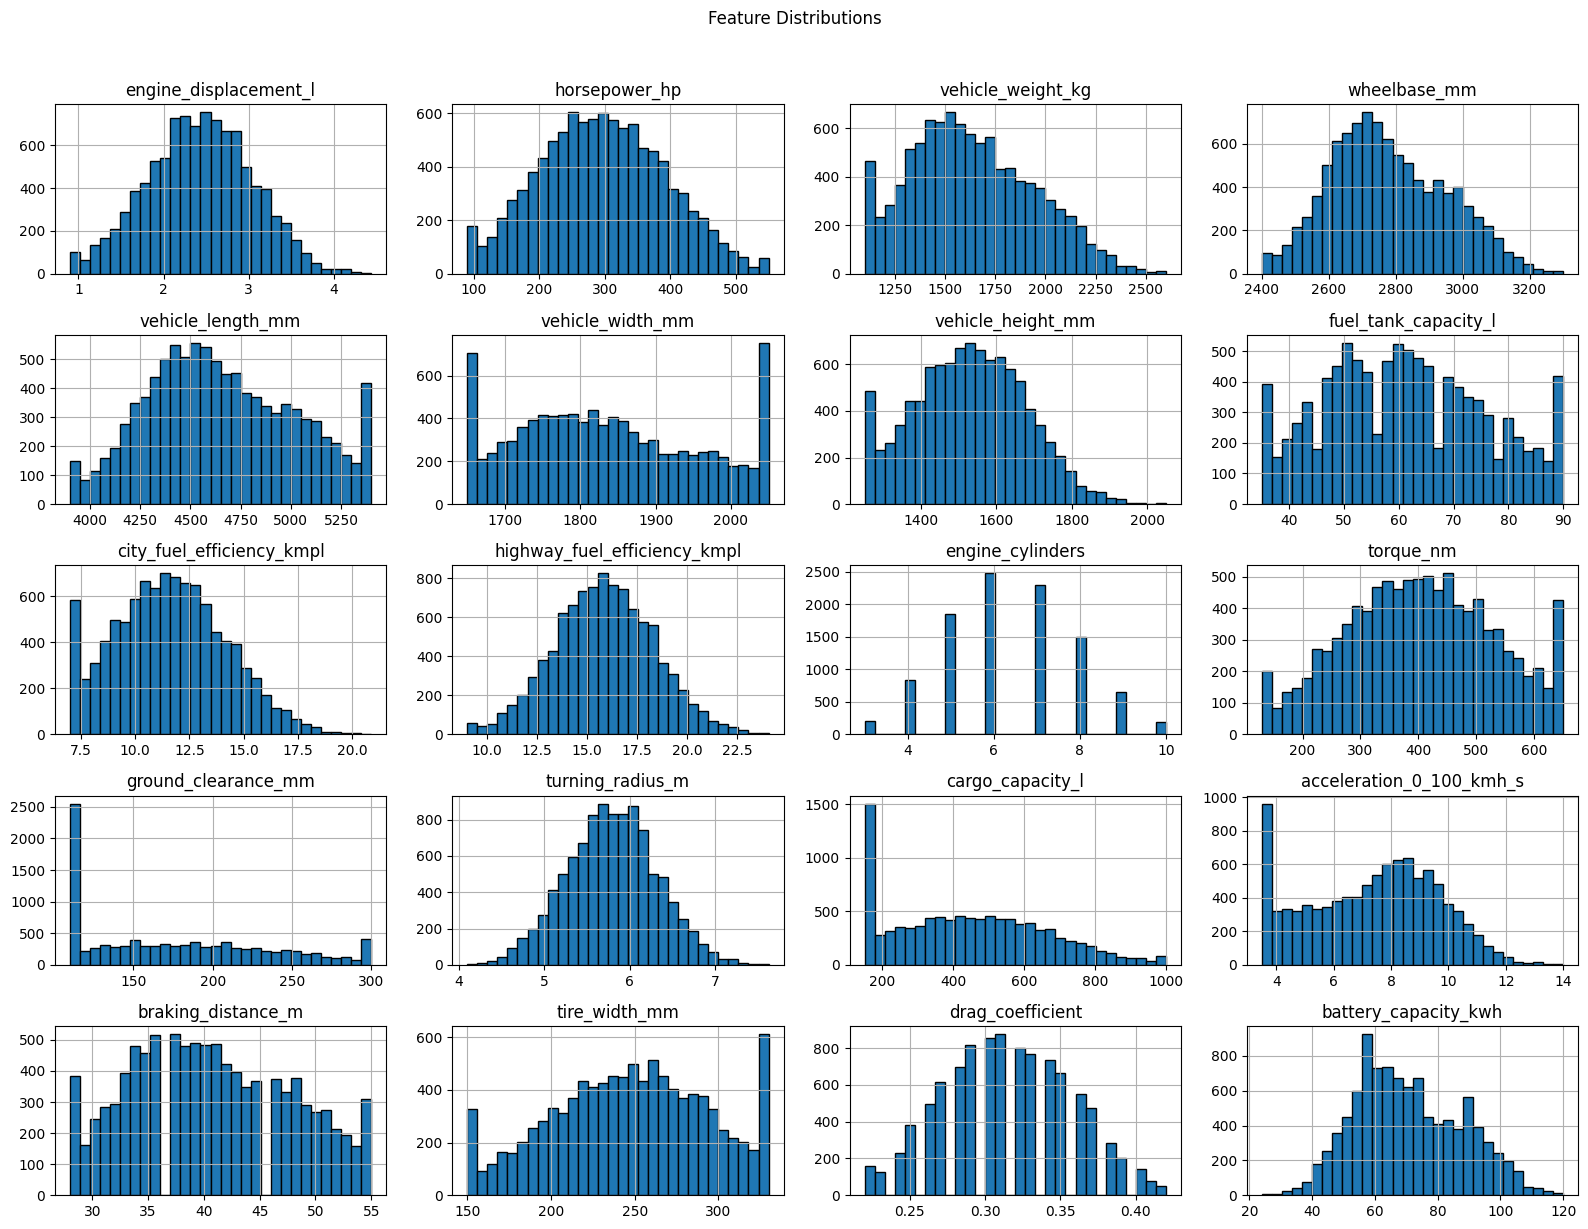

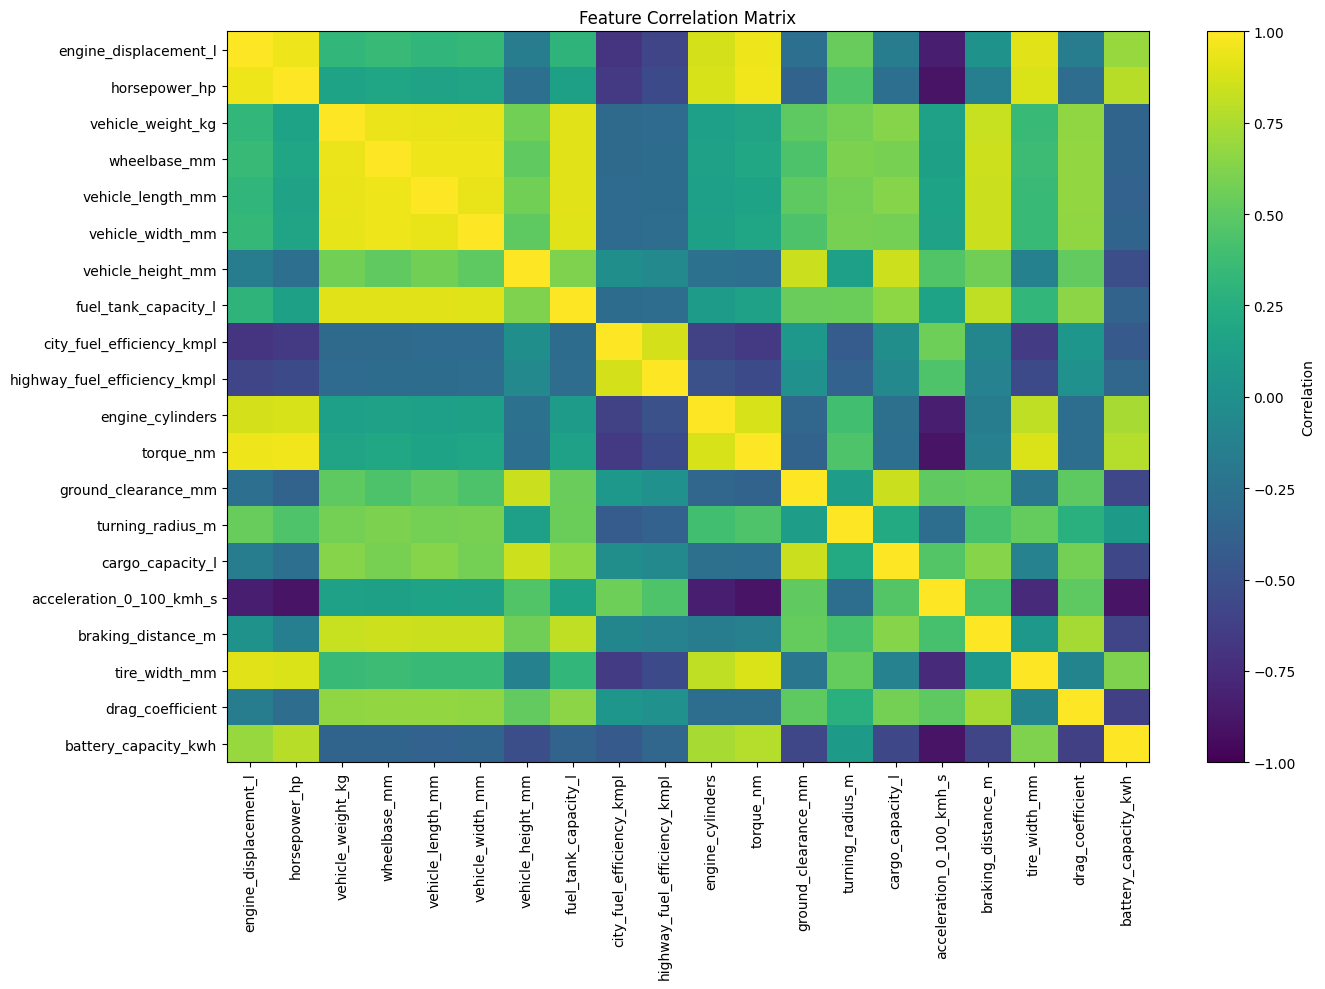

In [8]:
import matplotlib.pyplot as plt

class_counts = y.value_counts().sort_index()

print(class_counts)
print("\nClass proportions:")
print((y.value_counts(normalize=True).sort_index() * 100).round(2))

class_counts.plot(kind="bar", rot=0)
plt.title("Distribution of Vehicle Classes")
plt.xlabel("Vehicle Class")
plt.ylabel("Number of Rows")
plt.tight_layout()
plt.show()

# Identify numerical features
numeric_features = X.select_dtypes(include=np.number).columns.tolist()

print("Number of numerical features:", len(numeric_features))
print(numeric_features)

# Histograms
X[numeric_features].hist(
    figsize=(16, 12),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Feature Distributions", y=1.02)
plt.tight_layout()
plt.show()

correlation = X[numeric_features].corr()

plt.figure(figsize=(14, 10))
plt.imshow(correlation, aspect="auto", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(
    range(len(numeric_features)),
    numeric_features,
    rotation=90
)
plt.yticks(range(len(numeric_features)), numeric_features)
plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()

In [9]:
print("Categorical feature columns:")
print(X.select_dtypes(exclude=np.number).columns.tolist())

print("\nMissing values in X:", X.isnull().sum().sum())
print("Missing values in X_test:", X_test.isnull().sum().sum())

print(
    "Infinite values in numerical training features:",
    np.isinf(X.select_dtypes(include=np.number)).sum().sum()
)

print(
    "Infinite values in numerical test features:",
    np.isinf(X_test.select_dtypes(include=np.number)).sum().sum()
)

Categorical feature columns:
[]

Missing values in X: 0
Missing values in X_test: 0
Infinite values in numerical training features: 0
Infinite values in numerical test features: 0


In [10]:
from sklearn.feature_selection import VarianceThreshold

variances = X.var().sort_values()

print("Features with lowest variance:")
display(variances.head(10).to_frame("Variance"))

print("\nConstant features:")
print(variances[variances == 0].index.tolist())

Features with lowest variance:


,Variance
drag_coefficient,0.001816
turning_radius_m,0.275336
engine_displacement_l,0.377530
engine_cylinders,2.284150
acceleration_0_100_kmh_s,5.150055
highway_fuel_efficiency_kmpl,6.258427
city_fuel_efficiency_kmpl,6.583661
braking_distance_m,52.184876
fuel_tank_capacity_l,210.580242
battery_capacity_kwh,288.773653



Constant features:
[]


In [11]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

lr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("lr", LogisticRegression(
        max_iter=3000,
        random_state=42
    ))
])

print("Logistic Regression pipeline created successfully.")

Logistic Regression pipeline created successfully.


In [12]:
from sklearn.model_selection import StratifiedKFold, GridSearchCV

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

param_grid = [
    {
        "lr__C": [0.001, 0.01, 0.1, 1, 10, 100],
        "lr__penalty": ["l2"],
        "lr__solver": ["lbfgs"]
    },
    {
        "lr__C": [0.001, 0.01, 0.1, 1, 10, 100],
        "lr__penalty": ["l1", "l2"],
        "lr__solver": ["saga"]
    }
]

grid = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=param_grid,
    scoring="accuracy",
    cv=cv,
    n_jobs=-1,
    verbose=1,
    refit=True
)

print("Cross-validation and hyperparameter search are ready.")

Cross-validation and hyperparameter search are ready.


In [13]:
grid.fit(X, y)

print("\nBest hyperparameters:")
print(grid.best_params_)

print(f"\nBest mean 5-fold CV accuracy: {grid.best_score_:.2%}")
print(f"Random Forest benchmark: {92.87:.2f}%")
print(
    f"Difference: "
    f"{(grid.best_score_ - 0.9287) * 100:+.2f} percentage points"
)

Fitting 5 folds for each of 18 candidates, totalling 90 fits

Best hyperparameters:
{'lr__C': 0.1, 'lr__penalty': 'l2', 'lr__solver': 'saga'}

Best mean 5-fold CV accuracy: 89.58%
Random Forest benchmark: 92.87%
Difference: -3.29 percentage points


Validation accuracy: 88.40%

Classification report:
              precision    recall  f1-score   support

           0       0.84      0.83      0.83       678
           1       0.89      0.90      0.90       665
           2       0.93      0.92      0.93       657

    accuracy                           0.88      2000
   macro avg       0.88      0.88      0.88      2000
weighted avg       0.88      0.88      0.88      2000



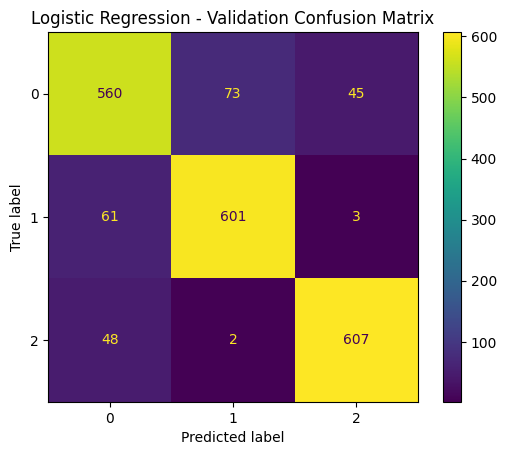

In [14]:

from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Split the training data into training and validation sets
X_train_lr, X_val_lr, y_train_lr, y_val_lr = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Create a fresh copy of the best Logistic Regression pipeline
best_lr = clone(grid.best_estimator_)

# Train the model
best_lr.fit(X_train_lr, y_train_lr)

# Predict the validation labels
y_val_pred_lr = best_lr.predict(X_val_lr)

# Evaluate the model
print(f"Validation accuracy: {accuracy_score(y_val_lr, y_val_pred_lr):.2%}")
print("\nClassification report:")
print(classification_report(y_val_lr, y_val_pred_lr))

# Display the confusion matrix
ConfusionMatrixDisplay.from_predictions(y_val_lr, y_val_pred_lr)
plt.title("Logistic Regression - Validation Confusion Matrix")
plt.show()


In [15]:

# Use the best hyperparameters found through 5-fold cross-validation
final_lr = clone(grid.best_estimator_)

# Train on the complete training dataset
final_lr.fit(X, y)

print("Final Logistic Regression model trained.")
print("Hyperparameters:", grid.best_params_)


Final Logistic Regression model trained.
Hyperparameters: {'lr__C': 0.1, 'lr__penalty': 'l2', 'lr__solver': 'saga'}


In [16]:

# Predict vehicle classes for the test dataset
test_predictions_lr = final_lr.predict(X_test)

print("Number of predictions:", len(test_predictions_lr))
print("First 10 predictions:", test_predictions_lr[:10])


Number of predictions: 2500
First 10 predictions: [0 0 1 2 1 0 1 1 2 2]


In [17]:

# Generate predictions for the test dataset
test_predictions_lr = final_lr.predict(X_test)

# Create the submission with the required columns and order
submission_lr = pd.DataFrame({
    "vehicle_id": test_df["vehicle_id"],
    "vehicle_class": test_predictions_lr
})

# Save the CSV file
submission_lr.to_csv("submission_logistic_regression.csv", index=False)

# Verify the submission
print(submission_lr.head())
print("\nSubmission shape:", submission_lr.shape)
print("\nColumns:", submission_lr.columns.tolist())
print("\nMissing values:", submission_lr.isnull().sum().sum())

assert submission_lr.columns.tolist() == ["vehicle_id", "vehicle_class"]
assert len(submission_lr) == len(test_df)
assert submission_lr["vehicle_class"].isin([0, 1, 2]).all()

print("\nSubmission file created and basic checks passed.")


   vehicle_id  vehicle_class
0       10001              0
1       10002              0
2       10003              1
3       10004              2
4       10005              1

Submission shape: (2500, 2)

Columns: ['vehicle_id', 'vehicle_class']

Missing values: 0

Submission file created and basic checks passed.


In [18]:

from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Standardize features before Logistic Regression
lr_pipeline_v2 = Pipeline([
    ("scaler", StandardScaler()),
    ("lr", LogisticRegression(
        max_iter=5000,
        random_state=42
    ))
])

# Explore a wider range of regularization strengths
param_grid_v2 = {
    "lr__C": [0.0001, 0.001, 0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30, 100],
    "lr__solver": ["lbfgs", "saga"],
    "lr__penalty": ["l2"]
}

cv_v2 = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_v2 = GridSearchCV(
    estimator=lr_pipeline_v2,
    param_grid=param_grid_v2,
    scoring="accuracy",
    cv=cv_v2,
    n_jobs=-1,
    verbose=1,
    refit=True
)

print("Expanded Logistic Regression search is ready.")


Expanded Logistic Regression search is ready.


In [19]:

grid_v2.fit(X, y)

print("Best hyperparameters:")
print(grid_v2.best_params_)

print(f"\nBest 5-fold CV accuracy: {grid_v2.best_score_:.4%}")
print(f"Previous Logistic Regression CV: {grid.best_score_:.4%}")
print("Previous leaderboard score: 0.90200")


Fitting 5 folds for each of 22 candidates, totalling 110 fits
Best hyperparameters:
{'lr__C': 0.1, 'lr__penalty': 'l2', 'lr__solver': 'saga'}

Best 5-fold CV accuracy: 89.5800%
Previous Logistic Regression CV: 89.5800%
Previous leaderboard score: 0.90200


In [20]:

from sklearn.preprocessing import RobustScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold

robust_lr_pipeline = Pipeline([
    ("scaler", RobustScaler()),
    ("lr", LogisticRegression(max_iter=5000, random_state=42))
])

robust_param_grid = {
    "lr__C": [0.01, 0.1, 1, 10, 100],
    "lr__solver": ["lbfgs", "saga"],
    "lr__penalty": ["l2"]
}

robust_grid = GridSearchCV(
    estimator=robust_lr_pipeline,
    param_grid=robust_param_grid,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    n_jobs=-1,
    verbose=1,
    refit=True
)

print("RobustScaler experiment is ready.")


RobustScaler experiment is ready.


In [21]:

robust_grid.fit(X, y)

print("Best hyperparameters:", robust_grid.best_params_)
print(f"RobustScaler CV accuracy: {robust_grid.best_score_:.4%}")
print(f"StandardScaler CV accuracy: {grid.best_score_:.4%}")
print("Current leaderboard baseline: 0.90200")


Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best hyperparameters: {'lr__C': 0.1, 'lr__penalty': 'l2', 'lr__solver': 'lbfgs'}
RobustScaler CV accuracy: 89.4400%
StandardScaler CV accuracy: 89.5800%
Current leaderboard baseline: 0.90200


In [22]:
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold

feature_selection_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("select", SelectKBest(score_func=f_classif)),
    ("lr", LogisticRegression(max_iter=5000, random_state=42))
])

feature_param_grid = {
    "select__k": [5, 8, 10, 15, 20],
    "lr__C": [0.01, 0.1, 1, 10],
    "lr__solver": ["lbfgs"],
    "lr__penalty": ["l2"]
}

feature_grid = GridSearchCV(
    estimator=feature_selection_pipeline,
    param_grid=feature_param_grid,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    n_jobs=-1,
    verbose=1
)

print("Feature-selection experiment is ready.")

Feature-selection experiment is ready.


In [23]:
feature_grid.fit(X, y)

print("Best hyperparameters:", feature_grid.best_params_)
print(f"Feature-selection CV accuracy: {feature_grid.best_score_:.4%}")
print(f"StandardScaler baseline: {grid.best_score_:.4%}")

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best hyperparameters: {'lr__C': 0.1, 'lr__penalty': 'l2', 'lr__solver': 'lbfgs', 'select__k': 20}
Feature-selection CV accuracy: 89.5700%
StandardScaler baseline: 89.5800%


In [24]:
#trial
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.model_selection import cross_val_score, StratifiedKFold

# Start from the original features; do not modify X itself.
X_eng = X.copy()

# Add features only when the required columns exist.
if {"horsepower_hp", "vehicle_weight_kg"}.issubset(X_eng.columns):
    X_eng["power_to_weight"] = (
        X_eng["horsepower_hp"] / X_eng["vehicle_weight_kg"]
    )

if {"torque_nm", "vehicle_weight_kg"}.issubset(X_eng.columns):
    X_eng["torque_to_weight"] = (
        X_eng["torque_nm"] / X_eng["vehicle_weight_kg"]
    )

if {"vehicle_length_mm", "vehicle_width_mm"}.issubset(X_eng.columns):
    X_eng["vehicle_footprint"] = (
        X_eng["vehicle_length_mm"] * X_eng["vehicle_width_mm"]
    )

if {"wheelbase_mm", "vehicle_length_mm"}.issubset(X_eng.columns):
    X_eng["wheelbase_ratio"] = (
        X_eng["wheelbase_mm"] / X_eng["vehicle_length_mm"]
    )

if {
    "highway_fuel_efficiency_kmpl",
    "city_fuel_efficiency_kmpl"
}.issubset(X_eng.columns):
    X_eng["fuel_efficiency_gap"] = (
        X_eng["highway_fuel_efficiency_kmpl"]
        - X_eng["city_fuel_efficiency_kmpl"]
    )

# Match the original 5-fold validation setup.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

engineered_model = clone(grid.best_estimator_)

scores = cross_val_score(
    engineered_model, X_eng, y,
    cv=cv, scoring="accuracy", n_jobs=-1
)

print(f"Original LR CV accuracy: {grid.best_score_:.4%}")
print(f"Engineered LR CV accuracy: {scores.mean():.4%}")
print(f"Fold standard deviation: {scores.std():.4%}")

Original LR CV accuracy: 89.5800%
Engineered LR CV accuracy: 89.5000%
Fold standard deviation: 0.4980%


In [25]:
#trial 2
print("Original shape:", X.shape)
print("Engineered shape:", X_eng.shape)
print("New features:", X_eng.columns.difference(X.columns).tolist())

Original shape: (10000, 20)
Engineered shape: (10000, 25)
New features: ['fuel_efficiency_gap', 'power_to_weight', 'torque_to_weight', 'vehicle_footprint', 'wheelbase_ratio']


In [26]:
# EDA setup: use only predictor columns; exclude ID and target from feature analysis
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

from sklearn.feature_selection import mutual_info_classif, f_classif
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
import seaborn as sns
import matplotlib.pyplot as plt

eda_features = X.select_dtypes(include=np.number).columns.tolist()
eda_df = train_df[eda_features].copy()
print(f"Rows: {len(train_df):,} | predictors: {len(eda_features)} | test rows: {len(test_df):,}")
print("Target labels:", sorted(y.unique().tolist()))
display(pd.DataFrame({
    "dtype": train_df[eda_features].dtypes.astype(str),
    "unique_values": train_df[eda_features].nunique(),
    "missing": train_df[eda_features].isna().sum(),
    "mean": train_df[eda_features].mean(),
    "std": train_df[eda_features].std(),
    "skew": train_df[eda_features].skew(),
    "kurtosis": train_df[eda_features].kurtosis()
}).sort_values("skew", key=lambda s: s.abs(), ascending=False).round(3))


Rows: 10,000 | predictors: 20 | test rows: 2,500
Target labels: [0, 1, 2]


,dtype,unique_values,missing,mean,std,skew,kurtosis
ground_clearance_mm,float64,191,0,176.306,58.252,0.487,-0.902
vehicle_weight_kg,float64,1271,0,1636.400,306.182,0.345,-0.483
cargo_capacity_l,float64,802,0,447.074,213.450,0.329,-0.696
wheelbase_mm,float64,806,0,2778.058,172.347,0.294,-0.481
battery_capacity_kwh,float64,95,0,70.532,16.993,0.284,-0.593
vehicle_width_mm,float64,401,0,1836.671,117.745,0.242,-0.966
city_fuel_efficiency_kmpl,float64,1083,0,11.612,2.566,0.224,-0.362
vehicle_length_mm,float64,1418,0,4660.039,366.060,0.201,-0.717
braking_distance_m,float64,28,0,40.683,7.224,0.182,-0.869
fuel_tank_capacity_l,float64,56,0,61.096,14.511,0.181,-0.789


,count,proportion_%
vehicle_class,,
0,3389,33.89
1,3326,33.26
2,3285,32.85


Majority-class accuracy baseline: 33.8900%


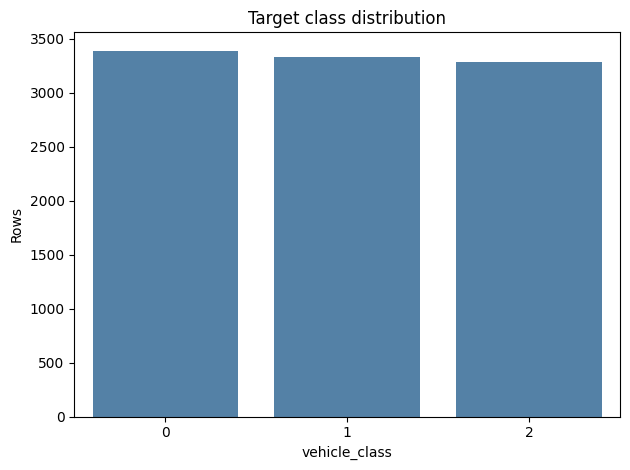

In [27]:
# 1. Target balance and majority-class baseline
class_summary = y.value_counts().sort_index().to_frame("count")
class_summary["proportion_%"] = (100 * class_summary["count"] / len(y)).round(2)
display(class_summary)
print(f"Majority-class accuracy baseline: {y.value_counts(normalize=True).max():.4%}")
ax = sns.countplot(x=y, color="steelblue")
ax.set(title="Target class distribution", xlabel="vehicle_class", ylabel="Rows")
plt.tight_layout()
plt.show()


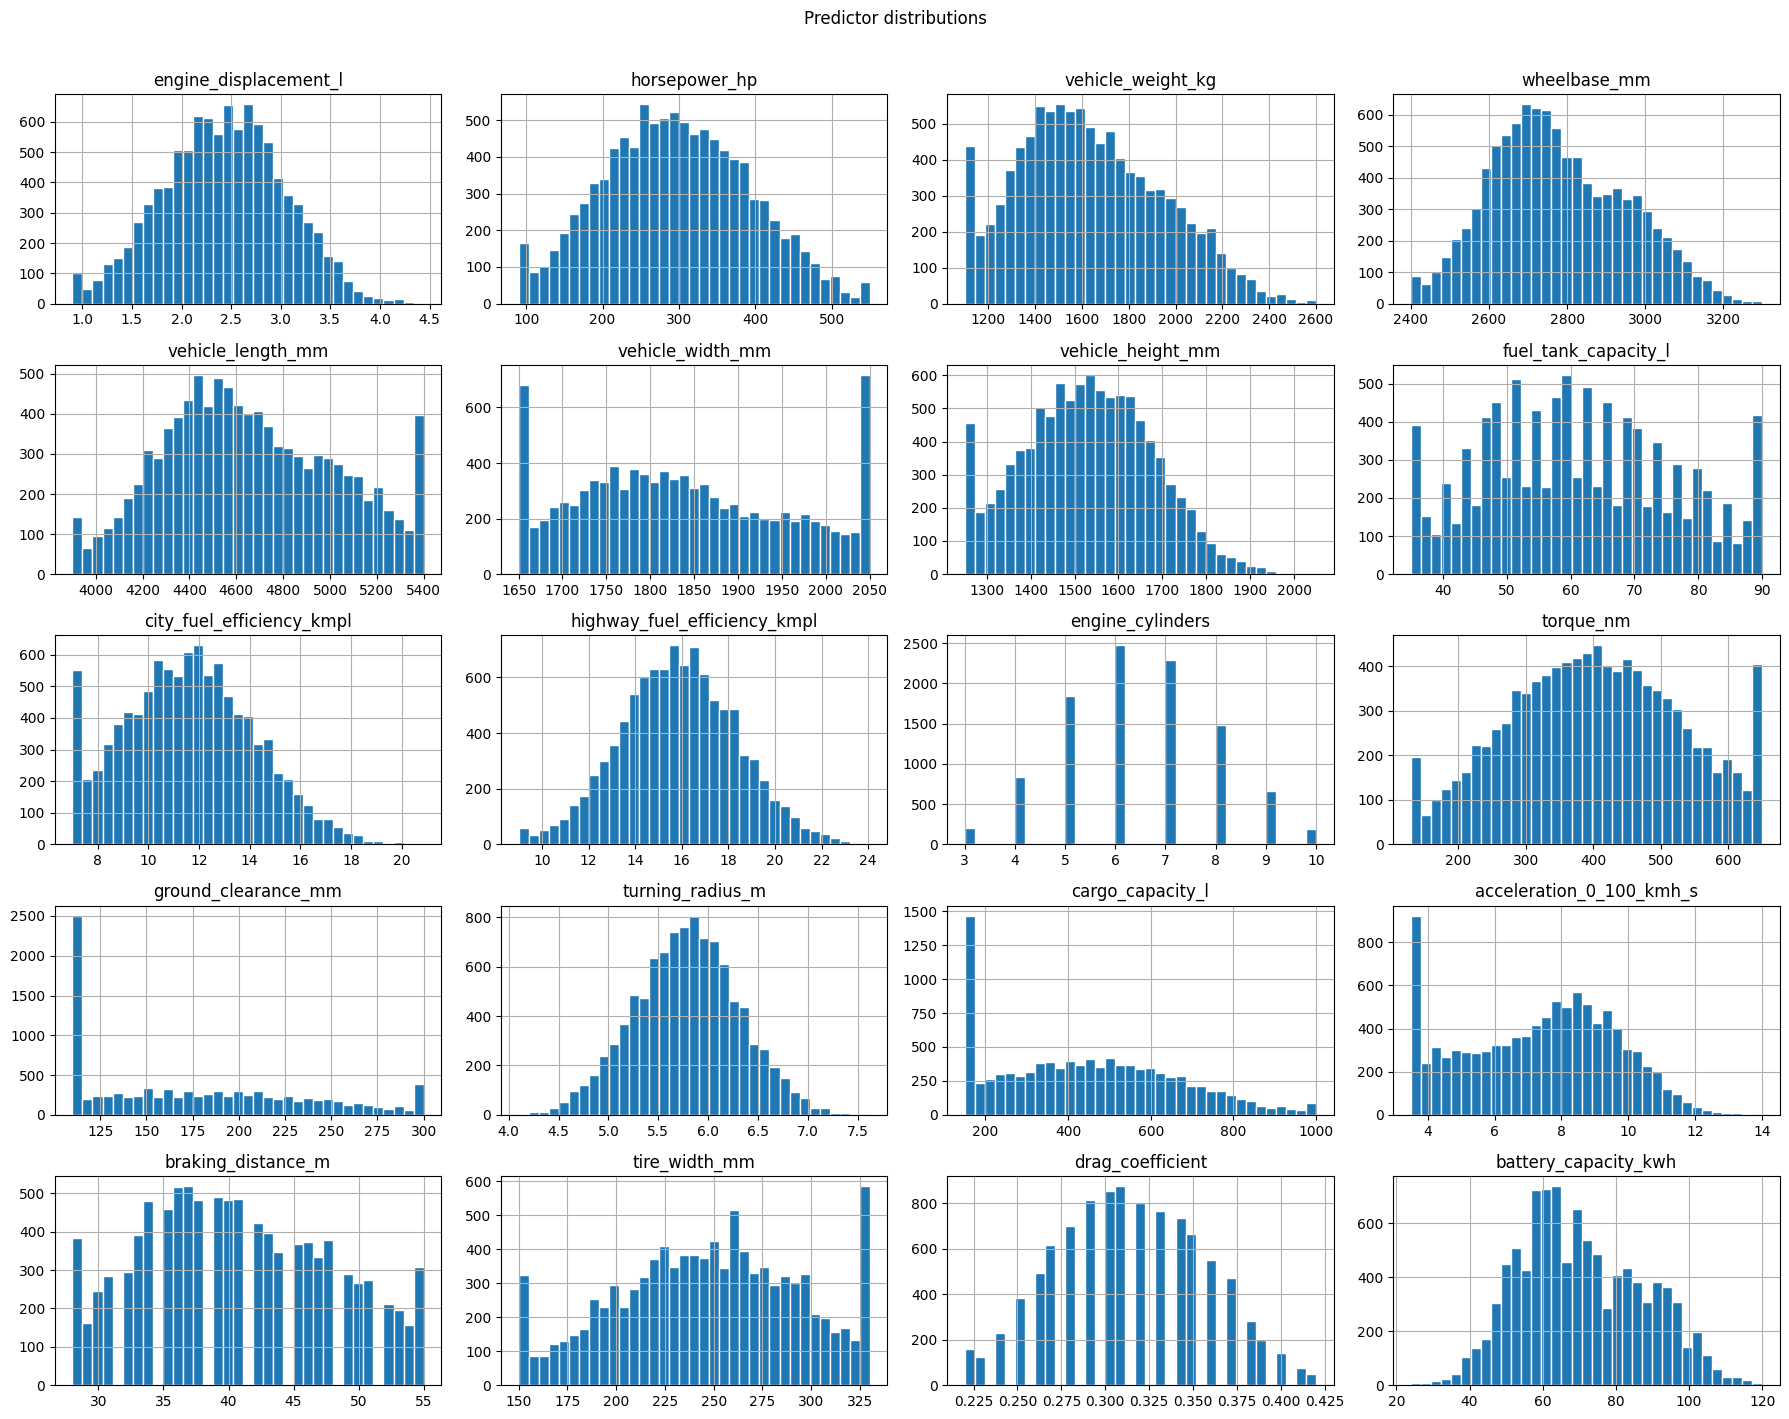

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
engine_displacement_l,10000.0,2.426,0.614,0.90,1.01,1.40,2.000,2.43,2.85,3.420,3.78,4.44
horsepower_hp,10000.0,296.495,95.564,90.00,90.00,142.00,226.000,294.00,364.00,458.000,512.01,550.00
vehicle_weight_kg,10000.0,1636.400,306.182,1100.00,1100.00,1159.95,1409.000,1604.00,1852.00,2173.000,2360.00,2600.00
wheelbase_mm,10000.0,2778.058,172.347,2400.00,2433.00,2516.00,2651.000,2756.00,2906.00,3082.000,3179.00,3300.00
vehicle_length_mm,10000.0,4660.039,366.060,3900.00,3900.00,4098.95,4387.750,4622.00,4937.00,5317.050,5400.00,5400.00
vehicle_width_mm,10000.0,1836.671,117.745,1650.00,1650.00,1650.00,1744.000,1824.00,1928.00,2050.000,2050.00,2050.00
vehicle_height_mm,10000.0,1528.945,145.979,1250.00,1250.00,1278.00,1423.000,1530.00,1634.00,1767.050,1868.00,2050.00
fuel_tank_capacity_l,10000.0,61.096,14.511,35.00,35.00,38.00,50.000,60.00,72.00,87.000,90.00,90.00
city_fuel_efficiency_kmpl,10000.0,11.612,2.566,7.00,7.00,7.25,9.750,11.56,13.36,15.970,17.85,20.87
highway_fuel_efficiency_kmpl,10000.0,15.851,2.502,9.00,9.99,11.73,14.160,15.83,17.55,19.961,21.80,24.07


In [28]:
# 2. Distributions: histogram + KDE for each predictor
eda_df.hist(figsize=(18, 14), bins=35, edgecolor="white", layout=(5, 4))
plt.suptitle("Predictor distributions", y=1.01)
plt.tight_layout()
plt.show()

# Numeric summary with robust quantiles
display(eda_df.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).T.round(3))


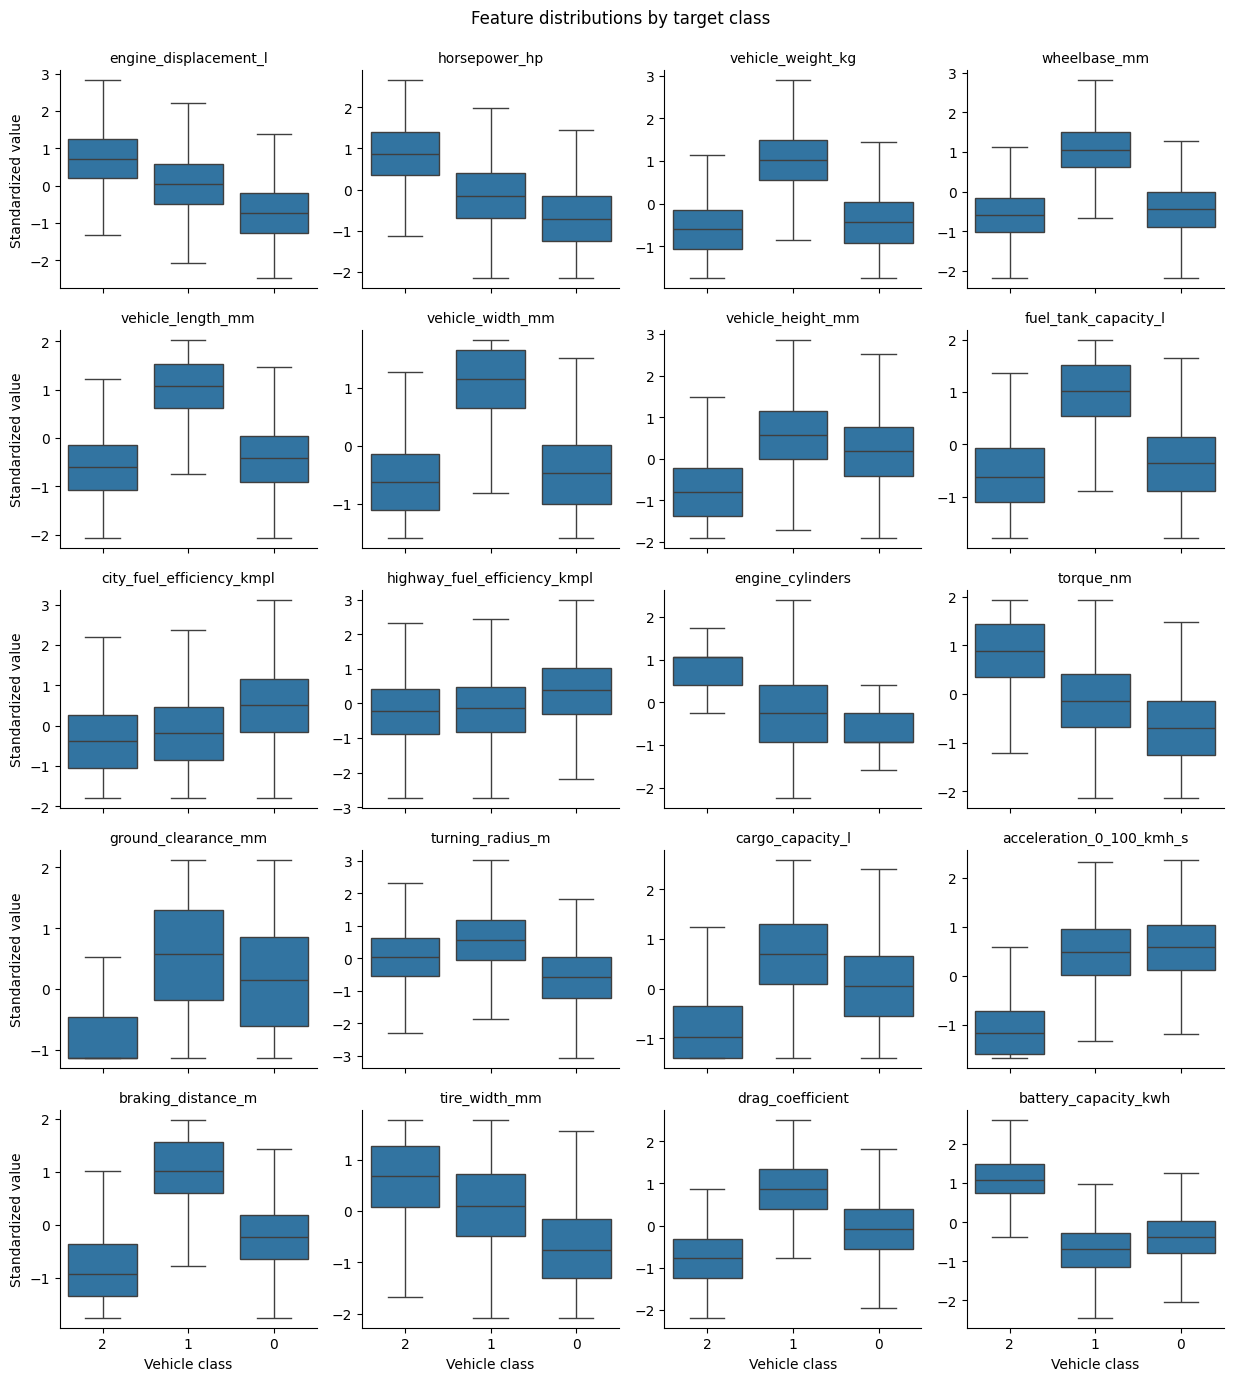

In [29]:
# 3. Class-conditional distributions. These reveal which features may separate classes.
# Standardized plots make features with different units easier to compare.
scaled_for_plot = pd.DataFrame(
    StandardScaler().fit_transform(eda_df),
    columns=eda_features,
    index=eda_df.index
)
scaled_for_plot["vehicle_class"] = y.astype(str).values
long_df = scaled_for_plot.melt(id_vars="vehicle_class", var_name="feature", value_name="standardized_value")
g = sns.catplot(
    data=long_df, x="vehicle_class", y="standardized_value",
    col="feature", col_wrap=4, kind="box", sharey=False,
    height=2.7, aspect=1.15, showfliers=False
)
g.set_titles("{col_name}")
g.set_axis_labels("Vehicle class", "Standardized value")
g.fig.suptitle("Feature distributions by target class", y=1.02)
plt.show()


In [30]:
# 4. Outlier screening using the IQR rule (screening only, not automatic deletion)
q1 = eda_df.quantile(0.25)
q3 = eda_df.quantile(0.75)
iqr = q3 - q1
outlier_mask = (eda_df < (q1 - 1.5 * iqr)) | (eda_df > (q3 + 1.5 * iqr))
outlier_summary = pd.DataFrame({
    "outlier_count_IQR": outlier_mask.sum(),
    "outlier_percent": (100 * outlier_mask.mean()).round(2),
    "min": eda_df.min(),
    "Q1": q1,
    "median": eda_df.median(),
    "Q3": q3,
    "max": eda_df.max()
}).sort_values("outlier_percent", ascending=False)
display(outlier_summary.round(3))
print("Important: IQR flags are not proof of bad data. Vehicle specifications can naturally have extreme values.")


,outlier_count_IQR,outlier_percent,min,Q1,median,Q3,max
highway_fuel_efficiency_kmpl,65,0.65,9.00,14.160,15.83,17.55,24.07
turning_radius_m,46,0.46,4.10,5.430,5.79,6.14,7.62
city_fuel_efficiency_kmpl,32,0.32,7.00,9.750,11.56,13.36,20.87
engine_displacement_l,25,0.25,0.90,2.000,2.43,2.85,4.44
vehicle_weight_kg,17,0.17,1100.00,1409.000,1604.00,1852.00,2600.00
vehicle_height_mm,10,0.10,1250.00,1423.000,1530.00,1634.00,2050.00
wheelbase_mm,7,0.07,2400.00,2651.000,2756.00,2906.00,3300.00
horsepower_hp,0,0.00,90.00,226.000,294.00,364.00,550.00
fuel_tank_capacity_l,0,0.00,35.00,50.000,60.00,72.00,90.00
vehicle_width_mm,0,0.00,1650.00,1744.000,1824.00,1928.00,2050.00


Important: IQR flags are not proof of bad data. Vehicle specifications can naturally have extreme values.


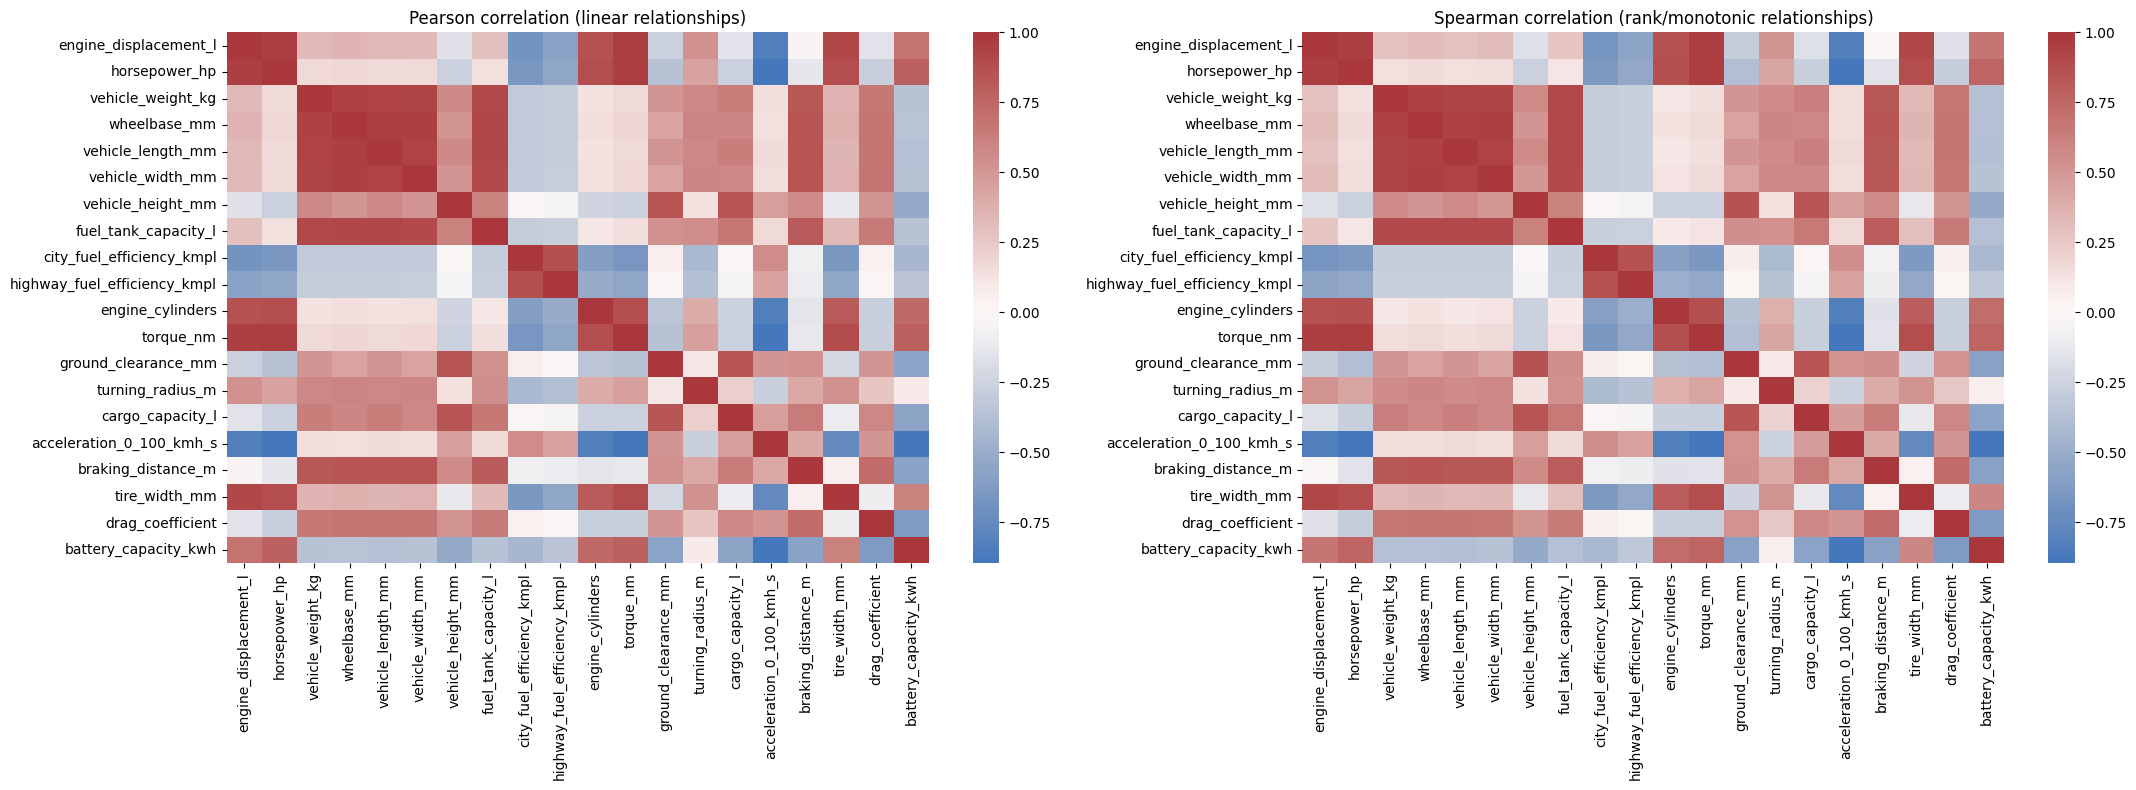

,feature_1,feature_2,correlation
28,horsepower_hp,torque_nm,0.959029
10,engine_displacement_l,torque_nm,0.952537
55,wheelbase_mm,vehicle_width_mm,0.951564
0,engine_displacement_l,horsepower_hp,0.950099
54,wheelbase_mm,vehicle_length_mm,0.948408
37,vehicle_weight_kg,wheelbase_mm,0.945055
70,vehicle_length_mm,vehicle_width_mm,0.937116
38,vehicle_weight_kg,vehicle_length_mm,0.934137
39,vehicle_weight_kg,vehicle_width_mm,0.929065
72,vehicle_length_mm,fuel_tank_capacity_l,0.913764


In [31]:
# 5. Correlation structure: Pearson and Spearman
pearson_corr = eda_df.corr(method="pearson")
spearman_corr = eda_df.corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(22, 8))
sns.heatmap(pearson_corr, cmap="vlag", center=0, ax=axes[0])
axes[0].set_title("Pearson correlation (linear relationships)")
sns.heatmap(spearman_corr, cmap="vlag", center=0, ax=axes[1])
axes[1].set_title("Spearman correlation (rank/monotonic relationships)")
plt.tight_layout()
plt.show()

# List highly correlated pairs to make the heatmap actionable
upper = pearson_corr.where(np.triu(np.ones(pearson_corr.shape), k=1).astype(bool))
pairs = upper.stack().rename("correlation").reset_index()
pairs.columns = ["feature_1", "feature_2", "correlation"]
display(pairs.loc[pairs["correlation"].abs() >= 0.80]
        .assign(abs_correlation=lambda d: d["correlation"].abs())
        .sort_values("abs_correlation", ascending=False).drop(columns="abs_correlation"))


,feature,ANOVA_F,ANOVA_p_value,mutual_information
16,braking_distance_m,8133.327306,0.0,0.449222
19,battery_capacity_kwh,8226.810788,0.0,0.447545
15,acceleration_0_100_kmh_s,6847.698129,0.0,0.433431
3,wheelbase_mm,6508.474061,0.0,0.419965
4,vehicle_length_mm,5977.948566,0.0,0.403393
2,vehicle_weight_kg,5640.957625,0.0,0.395039
5,vehicle_width_mm,6717.842480,0.0,0.393097
18,drag_coefficient,5050.993894,0.0,0.348671
7,fuel_tank_capacity_l,4899.382295,0.0,0.321532
11,torque_nm,3533.708976,0.0,0.286195


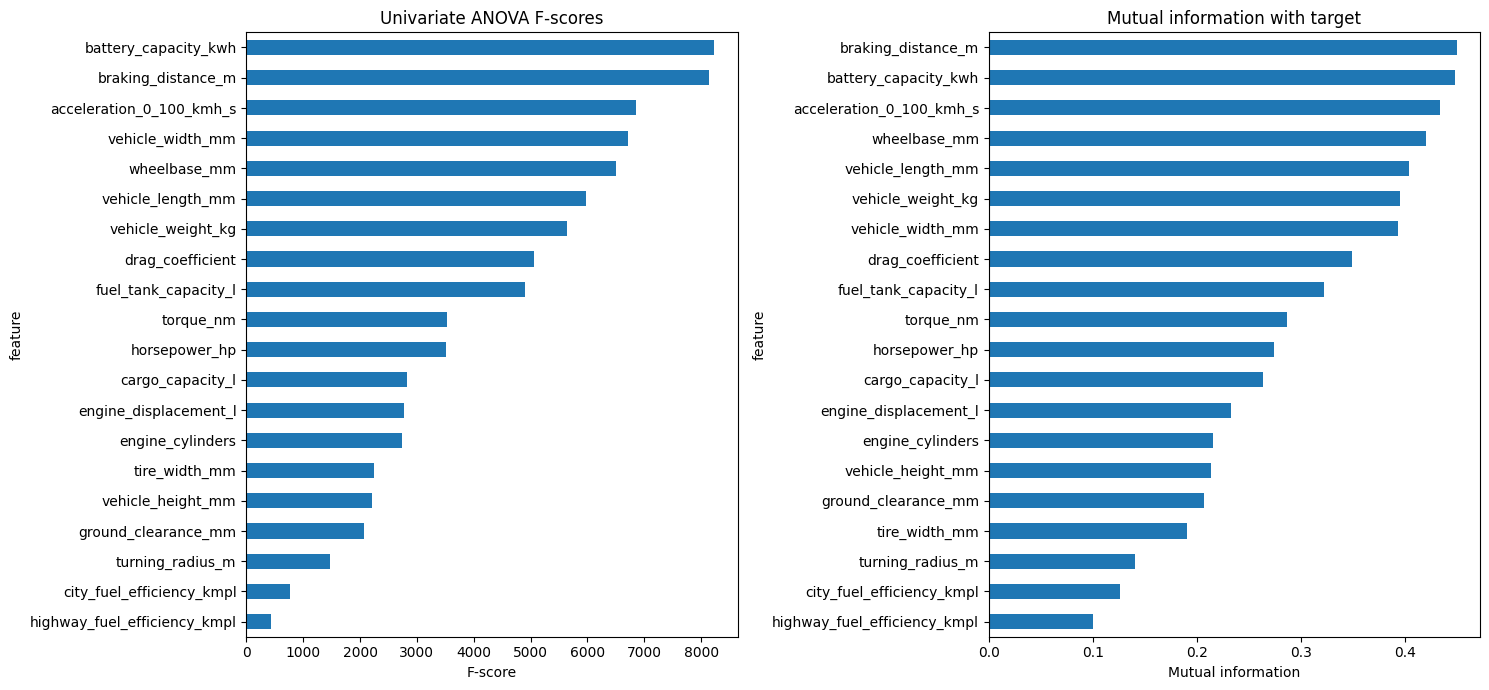

In [32]:
# 6. Feature–target association: ANOVA F-score and mutual information
# These are univariate screening tools, not proof of causal importance.
f_scores, p_values = f_classif(eda_df, y)
mi_scores = mutual_info_classif(eda_df, y, random_state=42)
association = pd.DataFrame({
    "feature": eda_features,
    "ANOVA_F": f_scores,
    "ANOVA_p_value": p_values,
    "mutual_information": mi_scores
}).sort_values("mutual_information", ascending=False)
display(association.round(6))

fig, axes = plt.subplots(1, 2, figsize=(15, 7))
association.sort_values("ANOVA_F").plot.barh(x="feature", y="ANOVA_F", ax=axes[0], legend=False)
axes[0].set_title("Univariate ANOVA F-scores")
axes[0].set_xlabel("F-score")
association.sort_values("mutual_information").plot.barh(x="feature", y="mutual_information", ax=axes[1], legend=False)
axes[1].set_title("Mutual information with target")
axes[1].set_xlabel("Mutual information")
plt.tight_layout()
plt.show()


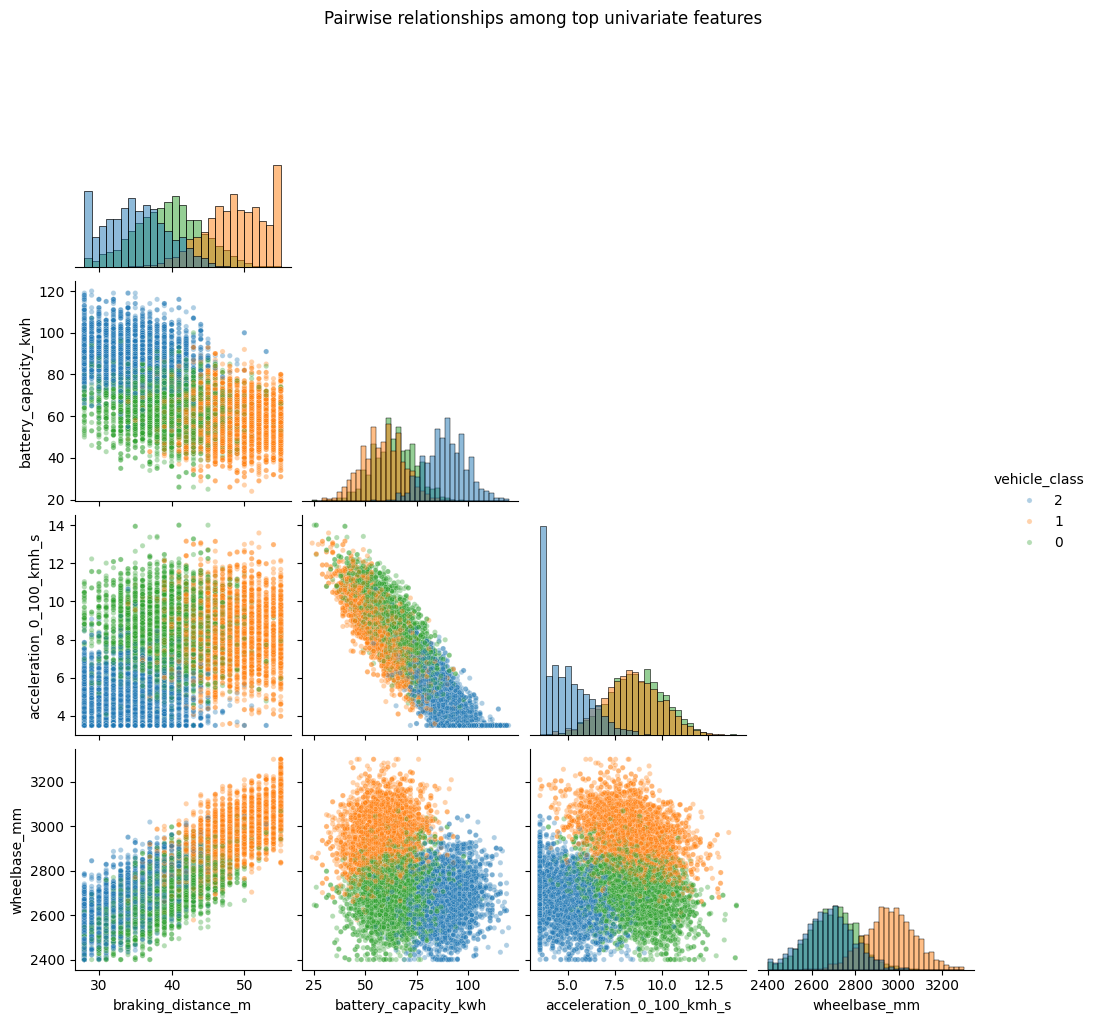

In [33]:
# 7. Pairwise plots for the strongest univariate features
top_features = association["feature"].head(4).tolist()
pairplot_df = train_df[top_features + [TARGET]].copy()
pairplot_df[TARGET] = pairplot_df[TARGET].astype(str)
sns.pairplot(pairplot_df, hue=TARGET, corner=True, diag_kind="hist", plot_kws={"alpha": 0.35, "s": 14})
plt.suptitle("Pairwise relationships among top univariate features", y=1.02)
plt.show()


Explained variance ratio: [0.4105 0.3852]
Total variance explained by first two PCs: 79.57%


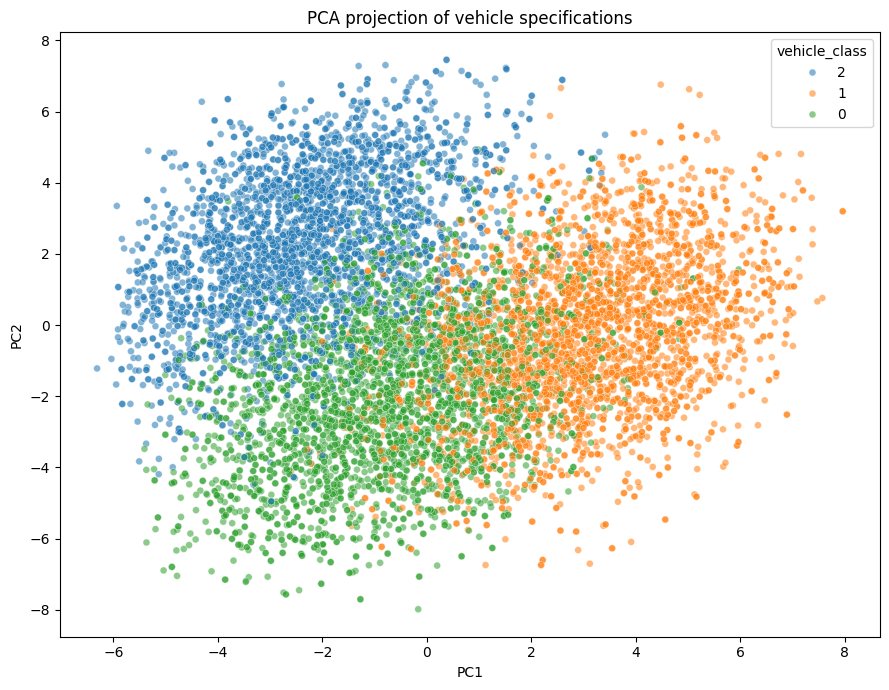

In [34]:
# 8. PCA view of class separability (visual diagnostic only)
# PCA is fit on standardized features, not the target.
Z = StandardScaler().fit_transform(eda_df)
pca = PCA(n_components=2, random_state=42)
Z_pca = pca.fit_transform(Z)
pca_df = pd.DataFrame({"PC1": Z_pca[:, 0], "PC2": Z_pca[:, 1], "vehicle_class": y.astype(str).values})
print("Explained variance ratio:", np.round(pca.explained_variance_ratio_, 4))
print("Total variance explained by first two PCs:", f"{pca.explained_variance_ratio_.sum():.2%}")
plt.figure(figsize=(9, 7))
sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="vehicle_class", alpha=0.55, s=25)
plt.title("PCA projection of vehicle specifications")
plt.tight_layout()
plt.show()


,feature,train_mean,test_mean,standardized_mean_difference,train_median,test_median,train_std,test_std
8,city_fuel_efficiency_kmpl,11.612,11.506,0.041,11.56,11.40,2.566,2.595
7,fuel_tank_capacity_l,61.096,61.580,-0.033,60.00,60.00,14.511,14.488
4,vehicle_length_mm,4660.039,4670.618,-0.029,4622.00,4637.00,366.060,363.336
0,engine_displacement_l,2.426,2.444,-0.029,2.43,2.44,0.614,0.635
3,wheelbase_mm,2778.058,2782.579,-0.026,2756.00,2763.00,172.347,172.926
17,tire_width_mm,246.998,248.186,-0.025,248.00,250.00,46.615,47.701
9,highway_fuel_efficiency_kmpl,15.851,15.787,0.025,15.83,15.73,2.502,2.578
2,vehicle_weight_kg,1636.400,1643.927,-0.024,1604.00,1614.00,306.182,308.285
1,horsepower_hp,296.495,298.800,-0.024,294.00,296.00,95.564,97.973
6,vehicle_height_mm,1528.945,1532.255,-0.023,1530.00,1533.00,145.979,143.496


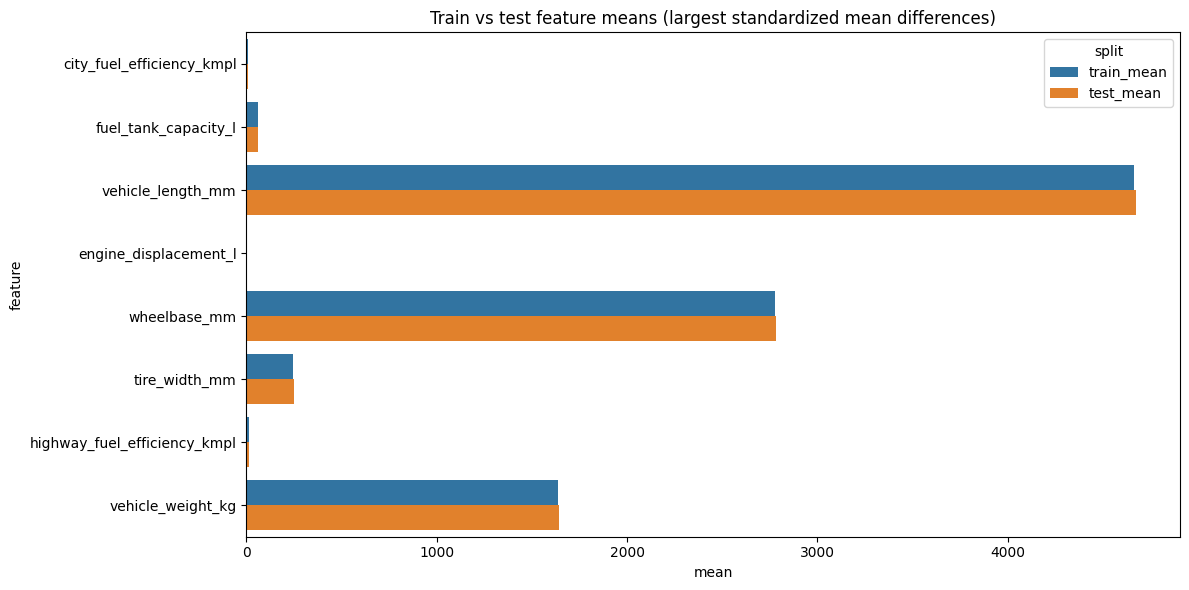

In [35]:
# 9. Train–test distribution shift: compare standardized mean differences and quantiles
# No target information is available for test rows, so this compares predictors only.
shift_rows = []
for col in eda_features:
    tr = train_df[col].dropna()
    te = test_df[col].dropna()
    pooled_sd = np.sqrt((tr.var(ddof=1) + te.var(ddof=1)) / 2)
    smd = (tr.mean() - te.mean()) / pooled_sd if pooled_sd > 0 else 0.0
    shift_rows.append({
        "feature": col,
        "train_mean": tr.mean(),
        "test_mean": te.mean(),
        "standardized_mean_difference": smd,
        "train_median": tr.median(),
        "test_median": te.median(),
        "train_std": tr.std(),
        "test_std": te.std()
    })
shift_df = pd.DataFrame(shift_rows)
display(shift_df.assign(abs_smd=lambda d: d["standardized_mean_difference"].abs())
        .sort_values("abs_smd", ascending=False).drop(columns="abs_smd").round(3))

# Visualize features with largest train/test mean differences
shift_top = shift_df.reindex(shift_df["standardized_mean_difference"].abs().sort_values(ascending=False).index).head(8)
plot_shift = shift_top.melt(id_vars="feature", value_vars=["train_mean", "test_mean"], var_name="split", value_name="mean")
plt.figure(figsize=(12, 6))
sns.barplot(data=plot_shift, x="mean", y="feature", hue="split")
plt.title("Train vs test feature means (largest standardized mean differences)")
plt.tight_layout()
plt.show()


In [36]:
# 10. Target-conditioned summary table
class_feature_means = train_df.groupby(TARGET)[eda_features].mean().T
class_feature_medians = train_df.groupby(TARGET)[eda_features].median().T
display(class_feature_means.round(2).rename(columns=lambda c: f"class_{c}_mean"))
display(class_feature_medians.round(2).rename(columns=lambda c: f"class_{c}_median"))


vehicle_class,class_0_mean,class_1_mean,class_2_mean
engine_displacement_l,1.97,2.45,2.87
horsepower_hp,230.57,282.25,378.93
vehicle_weight_kg,1503.65,1950.93,1454.89
wheelbase_mm,2697.35,2961.24,2675.86
vehicle_length_mm,4501.85,5040.89,4437.63
vehicle_width_mm,1780.76,1962.70,1766.75
vehicle_height_mm,1556.07,1611.06,1417.83
fuel_tank_capacity_l,55.49,75.44,52.36
city_fuel_efficiency_kmpl,12.88,11.23,10.69
highway_fuel_efficiency_kmpl,16.84,15.44,15.25


vehicle_class,class_0_median,class_1_median,class_2_median
engine_displacement_l,1.97,2.46,2.86
horsepower_hp,229.00,282.00,380.00
vehicle_weight_kg,1506.00,1950.00,1452.00
wheelbase_mm,2701.00,2961.00,2678.00
vehicle_length_mm,4508.00,5051.00,4437.00
vehicle_width_mm,1781.00,1972.00,1763.00
vehicle_height_mm,1556.00,1614.00,1413.00
fuel_tank_capacity_l,56.00,76.00,52.00
city_fuel_efficiency_kmpl,12.90,11.17,10.65
highway_fuel_efficiency_kmpl,16.80,15.49,15.28
